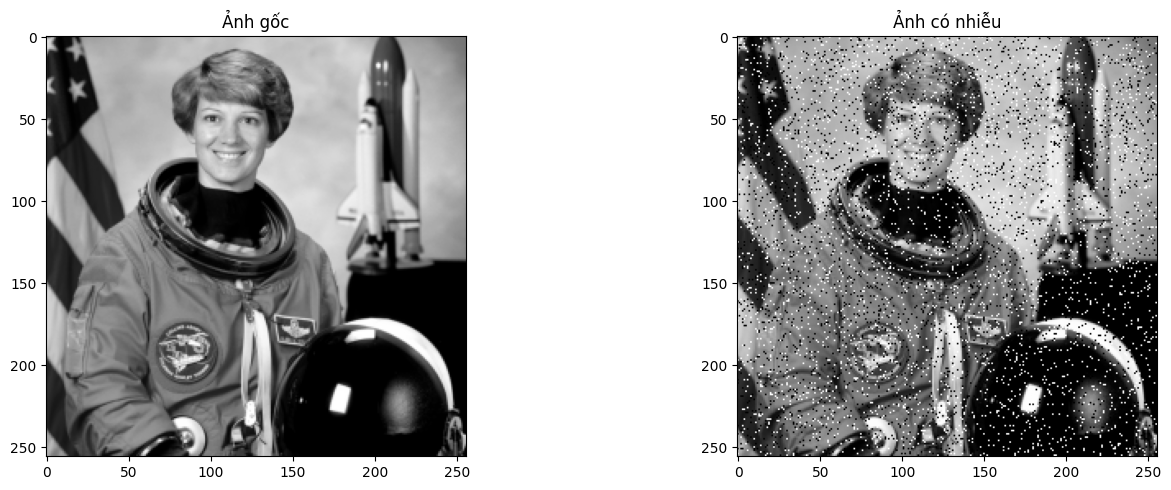

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, util
from skimage.color import rgb2gray
from skimage.transform import resize

image = data.astronaut()
gray = rgb2gray(image)
resized = resize(gray, (256, 256), anti_aliasing=True)
original = (resized * 255).astype(np.uint8)

noisy = util.random_noise(original, mode='s&p', amount=0.1)
noisy = (noisy * 255).astype(np.uint8)

# Hiển thị ảnh
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
axs[0].imshow(original, cmap='gray')
axs[0].set_title('Ảnh gốc')
axs[1].imshow(noisy, cmap='gray')
axs[1].set_title('Ảnh có nhiễu')

for ax in axs:
    ax.axis('on')
plt.tight_layout()
plt.show()


In [ ]:
def manual_mean_filter_verbose(img, k=3, max_print=5):
    pad = k // 2
    padded = np.pad(img, pad, mode='edge')
    result = np.zeros_like(img)

    print(f"{'='*10} Ma trận 3x3 và kết quả Mean {'='*10}")
    count = 0
    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            region = padded[i:i+k, j:j+k]
            mean_val = np.mean(region)
            result[i, j] = mean_val

            # in 5×5 điểm đầu tiên (vùng lân cận)
            if count < max_print**2:
                print(f"\nĐiểm ({i}, {j}):")
                print(region)
                print(f"Mean = {mean_val:.2f}")
            count += 1
    return result.astype(np.uint8)

In [ ]:
mean_filtered_verbose = manual_mean_filter_verbose(noisy, k=3, max_print=5)

========== Ma trận 3x3 và kết quả Mean ==========

Điểm (0, 0):
[[141 141  93]
 [141 141  93]
 [195 195 177]]
Mean = 146.33

Điểm (0, 1):
[[141  93 117]
 [141  93 117]
 [195 177 255]]
Mean = 147.67

Điểm (0, 2):
[[ 93 117 147]
 [ 93 117 147]
 [177 255 189]]
Mean = 148.33

Điểm (0, 3):
[[117 147 149]
 [117 147 149]
 [255 189   0]]
Mean = 141.11

Điểm (0, 4):
[[147 149 104]
 [147 149 104]
 [189   0  84]]
Mean = 119.22

Điểm (0, 5):
[[149 104  32]
 [149 104  32]
 [  0  84  17]]
Mean = 74.56

Điểm (0, 6):
[[104  32   4]
 [104  32   4]
 [ 84  17   5]]
Mean = 42.89

Điểm (0, 7):
[[32  4  1]
 [32  4  1]
 [17  5  1]]
Mean = 10.78

Điểm (0, 8):
[[4 1 3]
 [4 1 3]
 [5 1 0]]
Mean = 2.44

Điểm (0, 9):
[[1 3 9]
 [1 3 9]
 [1 0 8]]
Mean = 3.89

Điểm (0, 10):
[[ 3  9 13]
 [ 3  9 13]
 [ 0  8 13]]
Mean = 7.89

Điểm (0, 11):
[[ 9 13 13]
 [ 9 13 13]
 [ 8 13 13]]
Mean = 11.56

Điểm (0, 12):
[[13 13 12]
 [13 13 12]
 [13 13 12]]
Mean = 12.67

Điểm (0, 13):
[[ 13  12  12]
 [ 13  12  12]
 [ 13  12 255]]
Mean = 

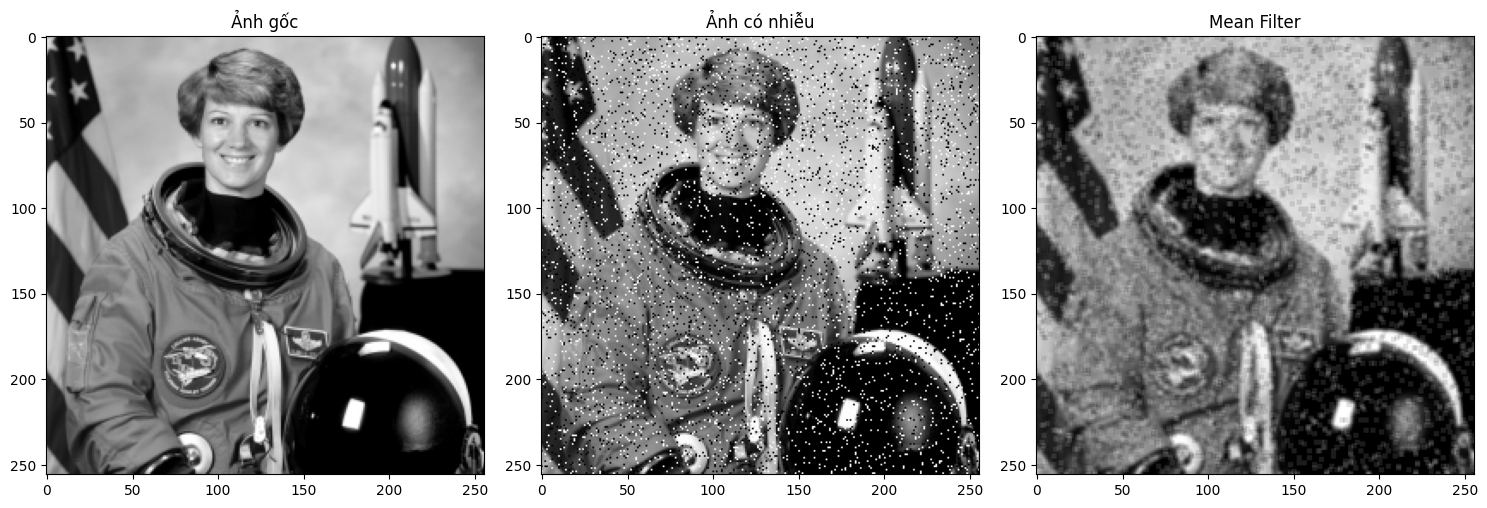

In [ ]:
# Hàm lọc trung bình
def manual_mean_filter(img, k=3):
    pad = k // 2
    padded = np.pad(img, pad, mode='edge')
    result = np.zeros_like(img)

    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            region = padded[i:i+k, j:j+k]
            result[i, j] = np.mean(region)

    return result.astype(np.uint8)

mean_filtered = manual_mean_filter(noisy, k=3)

# Hiển thị ảnh
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(original, cmap='gray')
axs[0].set_title('Ảnh gốc')
axs[1].imshow(noisy, cmap='gray')
axs[1].set_title('Ảnh có nhiễu')
axs[2].imshow(mean_filtered, cmap='gray')
axs[2].set_title('Mean Filter')

for ax in axs:
    ax.axis('on')
plt.tight_layout()
plt.show()

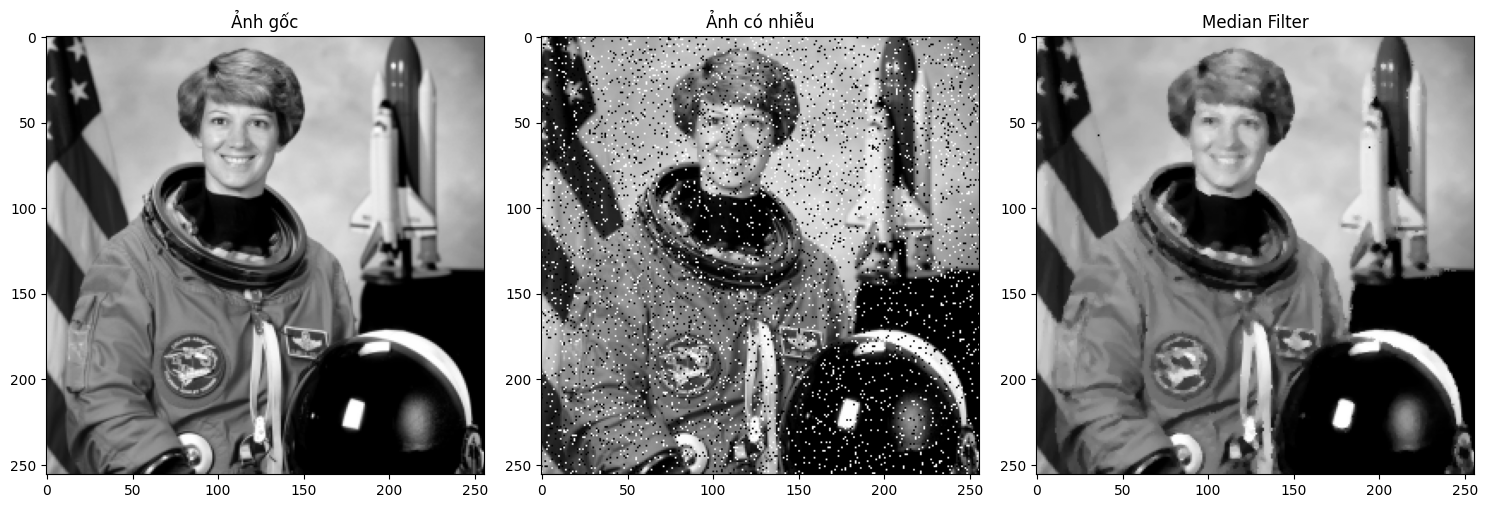

In [ ]:
# Hàm lọc trung vị
def manual_median_filter(img, k=3):
    # BEGIN CODE
    pad = k//2
    padded = np.pad(img, pad, mode='edge')
    result = np.zeros_like(img)
    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            result[i,j] = np.median(padded[i:i+k, j:j+k])
    return result
    # END CODE

median_filtered = manual_median_filter(noisy, k=3)

# Hiển thị ảnh
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(original, cmap='gray')
axs[0].set_title('Ảnh gốc')
axs[1].imshow(noisy, cmap='gray')
axs[1].set_title('Ảnh có nhiễu')
axs[2].imshow(median_filtered, cmap='gray')
axs[2].set_title('Median Filter')

for ax in axs:
    ax.axis('on')
plt.tight_layout()
plt.show()